In [118]:
import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

In [119]:
df = pd.read_csv("Churn.csv")

print("Initial Columns:")
print(df.columns)

Initial Columns:
Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')


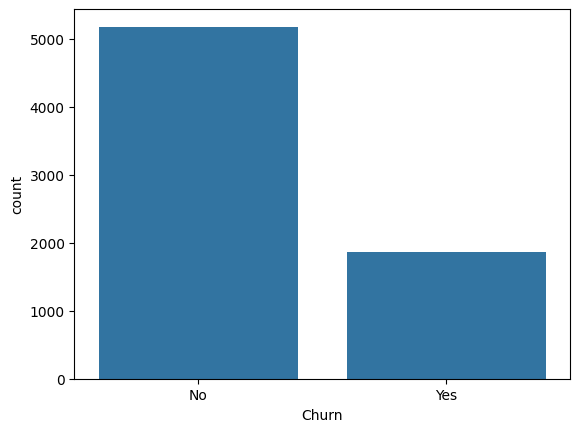

In [120]:
sns.countplot(x='Churn', data=df)
plt.show()

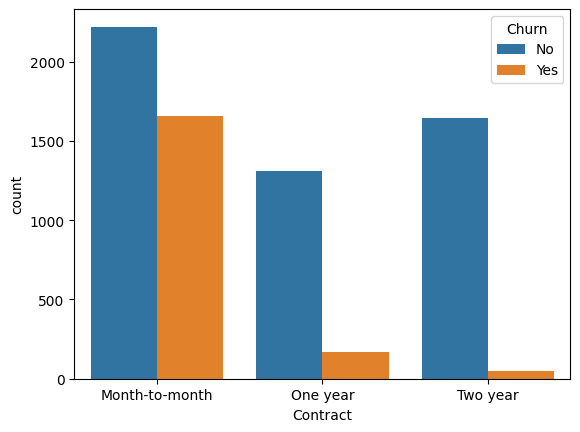

In [121]:
sns.countplot(x='Contract', hue='Churn', data=df)
plt.show()

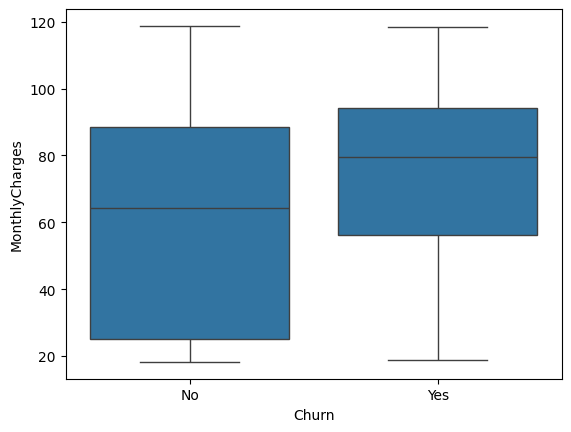

In [122]:
sns.boxplot(x='Churn', y='MonthlyCharges', data=df)
plt.show()

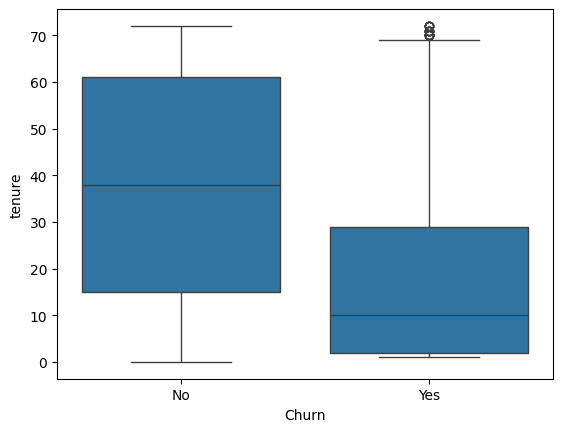

In [123]:
sns.boxplot(x='Churn', y='tenure', data=df)
plt.show()

In [124]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df.dropna(inplace=True)

In [125]:
df['Churn'] = df['Churn'].map({'Yes':1, 'No':0})

In [126]:
df.drop('customerID', axis=1, inplace=True)

In [127]:
df = pd.get_dummies(df, drop_first=True)

In [128]:
print([col for col in df.columns if 'customerID' in col])

[]


In [129]:
X = df.drop('Churn', axis=1)
y = df['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [130]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [131]:
model = LogisticRegression(max_iter=500, solver='liblinear', class_weight='balanced')
model.fit(X_train, y_train)

LogisticRegression(class_weight='balanced', max_iter=500, solver='liblinear')

In [132]:
y_pred = model.predict(X_test)

In [133]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.90      0.71      0.80      1033
           1       0.50      0.79      0.61       374

    accuracy                           0.73      1407
   macro avg       0.70      0.75      0.70      1407
weighted avg       0.80      0.73      0.75      1407



In [134]:
importance = model.coef_[0]

feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': importance
})

feature_importance = feature_importance.sort_values(by='Importance', ascending=False)


In [135]:
print(feature_importance.head(10))

                           Feature  Importance
10     InternetService_Fiber optic    0.732298
3                     TotalCharges    0.654160
23             StreamingMovies_Yes    0.262224
21                 StreamingTV_Yes    0.257017
9                MultipleLines_Yes    0.162153
28  PaymentMethod_Electronic check    0.139775
26            PaperlessBilling_Yes    0.120744
0                    SeniorCitizen    0.095210
17            DeviceProtection_Yes    0.050718
5                      Partner_Yes    0.020210


In [136]:
df['Churn_Prediction'] = model.predict(scaler.transform(X))

df.to_csv("final_churn_data.csv", index=False)